# Step 5g.bis — SVM climate x soil (trained on ERA5, MIRCA2000 sans seuil) vs GAEZ v5's own future suitability, ISIMIP MRI-ESM2-0 SSP585

Meme comparaison que `5.g)`, climat/modele repointes vers la branche MIRCA2000 sans seuil (`3.quater)`/`4.d)`/`4.f.bis)` -- voir [[mirca-5pct-presence-threshold-dilution]]). Sol (High input, GAEZ Module IV) et produit futur GAEZ v5 natif inchanges.

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, rasterio, xarray as xr
from rasterio.windows import Window
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import pearsonr

BASE        = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
ERA5_DIR    = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "1.1)_preprocessing_biovariables_ERA5" / "outputs_ERA5_MIRCA2000_no_threshold"
CLIMATE_FUTURE_DIR = BASE / "1_SVM" / "4_SVM_predict" / "4.f)_svm_predict_isimip_mri-esm" / "svm_predict_outputs_ISIMIP_MRI-ESM2-0_ssp585_2061_2080_no_threshold"
SOIL_DIR    = BASE / "1_SVM" / "2_soil_suitability_gaez" / "soil_suitability_outputs"
GAEZ_DIR    = cu.data_dir(CFG, "gaez_v5_future")  # data path: see 00_config_and_inventory.ipynb
OUT_DIR     = BASE / "1_SVM" / "5_Suitability_climate_soil_combined_validation" / "5.g)_svm_vs_gaez_future_ISIMIP_MRI" / "future_isimip_vs_gaez_outputs_no_threshold"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROPS = ['Maize_rf', 'Wheat-spring_rf', 'Wheat-winter_rf', 'Potato_rf']
GAEZ_CODE = {'Maize_rf': 'MZE', 'Wheat-spring_rf': 'WHE', 'Wheat-winter_rf': 'WHE', 'Potato_rf': 'WPO'}
GAEZ_FUTURE_PATHS = {crop: GAEZ_DIR / f'GAEZ-V5.RES05-SXX.FP6180.MRI-ESM2-0.SSP585.{GAEZ_CODE[crop]}.HRLM.tif'
                     for crop in CROPS}

print("Input files:")
for crop in CROPS:
    for p in [CLIMATE_FUTURE_DIR / f'suitability_ISIMIP_MRI-ESM2-0_ssp585_2061_2080_{crop}.nc',
              SOIL_DIR / f'soil_suitability_{crop}_1deg_x0grid_high.nc', GAEZ_FUTURE_PATHS[crop]]:
        print(f'  {"OK" if p.exists() else "MISSING"}: {p.name}')

Input files:
  OK: suitability_ISIMIP_MRI-ESM2-0_ssp585_2061_2080_Maize_rf.nc
  OK: soil_suitability_Maize_rf_1deg_x0grid_high.nc
  OK: GAEZ-V5.RES05-SXX.FP6180.MRI-ESM2-0.SSP585.MZE.HRLM.tif
  OK: suitability_ISIMIP_MRI-ESM2-0_ssp585_2061_2080_Wheat-spring_rf.nc
  OK: soil_suitability_Wheat-spring_rf_1deg_x0grid_high.nc
  OK: GAEZ-V5.RES05-SXX.FP6180.MRI-ESM2-0.SSP585.WHE.HRLM.tif
  OK: suitability_ISIMIP_MRI-ESM2-0_ssp585_2061_2080_Wheat-winter_rf.nc
  OK: soil_suitability_Wheat-winter_rf_1deg_x0grid_high.nc
  OK: GAEZ-V5.RES05-SXX.FP6180.MRI-ESM2-0.SSP585.WHE.HRLM.tif
  OK: suitability_ISIMIP_MRI-ESM2-0_ssp585_2061_2080_Potato_rf.nc
  OK: soil_suitability_Potato_rf_1deg_x0grid_high.nc
  OK: GAEZ-V5.RES05-SXX.FP6180.MRI-ESM2-0.SSP585.WPO.HRLM.tif


## 1. Grid, climate (4.f), soil (High input), combined

In [2]:
ds_grid = xr.open_dataset(ERA5_DIR / 'BIOvariables_ERA5_1981_2015_1deg_Maize_rf.nc')
target_lats_asc = ds_grid.lat.values
target_lons     = ds_grid.lon.values
ds_grid.close()

land_mask = np.zeros((len(target_lats_asc), len(target_lons)), dtype=bool)
for crop in CROPS:
    ds_c = xr.open_dataset(ERA5_DIR / f'BIOvariables_ERA5_1981_2015_1deg_{crop}.nc')
    land_mask |= np.isfinite(ds_c['BIO01'].values)
    ds_c.close()

nlat, nlon = len(target_lats_asc), len(target_lons)
LAT_MIN_EDGE, LAT_MAX_EDGE = target_lats_asc[0] - 0.5, target_lats_asc[-1] + 0.5
LON_MIN_EDGE, LON_MAX_EDGE = target_lons[0] - 0.5, target_lons[-1] + 0.5
ext = [LON_MIN_EDGE, LON_MAX_EDGE, LAT_MIN_EDGE, LAT_MAX_EDGE]


def load_climate_future(crop):
    ds = xr.open_dataset(CLIMATE_FUTURE_DIR / f'suitability_ISIMIP_MRI-ESM2-0_ssp585_2061_2080_{crop}.nc')
    arr = ds['suit_proba'].values
    ds.close()
    return arr


def load_soil_high(crop):
    ds = xr.open_dataset(SOIL_DIR / f'soil_suitability_{crop}_1deg_x0grid_high.nc')
    arr = ds[list(ds.data_vars)[0]].values / 100.0
    ds.close()
    return arr


suit_climate_future = {crop: load_climate_future(crop) for crop in CROPS}
soil_high = {crop: load_soil_high(crop) for crop in CROPS}
suit_combined_future = {crop: suit_climate_future[crop] * soil_high[crop] for crop in CROPS}

for crop in CROPS:
    print(f'{crop:18s}: climate mean={np.nanmean(suit_climate_future[crop][land_mask]):.3f}  '
          f'soil mean={np.nanmean(soil_high[crop][land_mask]):.3f}  '
          f'combined mean={np.nanmean(suit_combined_future[crop][land_mask]):.3f}')

Maize_rf          : climate mean=0.860  soil mean=0.551  combined mean=0.503
Wheat-spring_rf   : climate mean=0.368  soil mean=0.600  combined mean=0.241
Wheat-winter_rf   : climate mean=0.829  soil mean=0.600  combined mean=0.527
Potato_rf         : climate mean=0.861  soil mean=0.484  combined mean=0.442


## 2. GAEZ v5's own future suitability (RES05-SXX, continuous 0-10000 -> 0-1)

In [3]:
def load_gaez_future_native(path):
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count)).astype(float)
    raw[(raw < 0) | (raw > 10000)] = np.nan
    return raw / 10000.0  # north-up, same convention as the raw raster


def load_gaez_future_1deg(path):
    with rasterio.open(path) as src:
        res = src.transform.a
        ulx, uly = src.transform.c, src.transform.f
        px_per_deg = round(1.0 / res)
        col_start = round((LON_MIN_EDGE - ulx) / res)
        row_start = round((uly - LAT_MAX_EDGE) / res)
        col_count = round((LON_MAX_EDGE - LON_MIN_EDGE) / res)
        row_count = round((LAT_MAX_EDGE - LAT_MIN_EDGE) / res)
        raw = src.read(1, window=Window(col_start, row_start, col_count, row_count)).astype(float)
    raw[(raw < 0) | (raw > 10000)] = np.nan
    score = raw / 10000.0
    assert score.shape == (nlat * px_per_deg, nlon * px_per_deg)
    blocks = score.reshape(nlat, px_per_deg, nlon, px_per_deg)
    with np.errstate(invalid='ignore'):
        out = np.nanmean(blocks, axis=(1, 3))[::-1, :]
    return np.where(land_mask, out, np.nan)


gaez_future_native = {crop: load_gaez_future_native(GAEZ_FUTURE_PATHS[crop]) for crop in CROPS}
gaez_future_1deg   = {crop: load_gaez_future_1deg(GAEZ_FUTURE_PATHS[crop]) for crop in CROPS}

corr_rows = []
for crop in CROPS:
    for label, arr in [('climate_only', suit_climate_future[crop]), ('combined (climate x soil)', suit_combined_future[crop])]:
        both = np.isfinite(arr) & np.isfinite(gaez_future_1deg[crop]) & land_mask
        r, _ = pearsonr(arr[both], gaez_future_1deg[crop][both])
        corr_rows.append(dict(crop=crop, layer=label, n=int(both.sum()), pearson_r=round(r, 3),
                              ours_mean=round(float(np.nanmean(arr[land_mask])), 3),
                              gaez_mean=round(float(np.nanmean(gaez_future_1deg[crop][land_mask])), 3)))
corr_df = pd.DataFrame(corr_rows)
print(corr_df.to_string(index=False))
corr_df.to_csv(OUT_DIR / 'validation_summary_future_ISIMIP_vs_GAEZ.csv', index=False)

           crop                     layer    n  pearson_r  ours_mean  gaez_mean
       Maize_rf              climate_only 1332      0.458      0.860      0.303
       Maize_rf combined (climate x soil) 1330      0.853      0.503      0.303
Wheat-spring_rf              climate_only 1332      0.272      0.368      0.395
Wheat-spring_rf combined (climate x soil) 1330      0.498      0.241      0.395
Wheat-winter_rf              climate_only 1332      0.484      0.829      0.395
Wheat-winter_rf combined (climate x soil) 1330      0.799      0.527      0.395
      Potato_rf              climate_only 1332      0.460      0.861      0.358
      Potato_rf combined (climate x soil) 1330      0.896      0.442      0.358


## 3. Maps -- SVM climate x soil (ERA5/our soil, ISIMIP 2061-2080) vs GAEZ v5's own future product

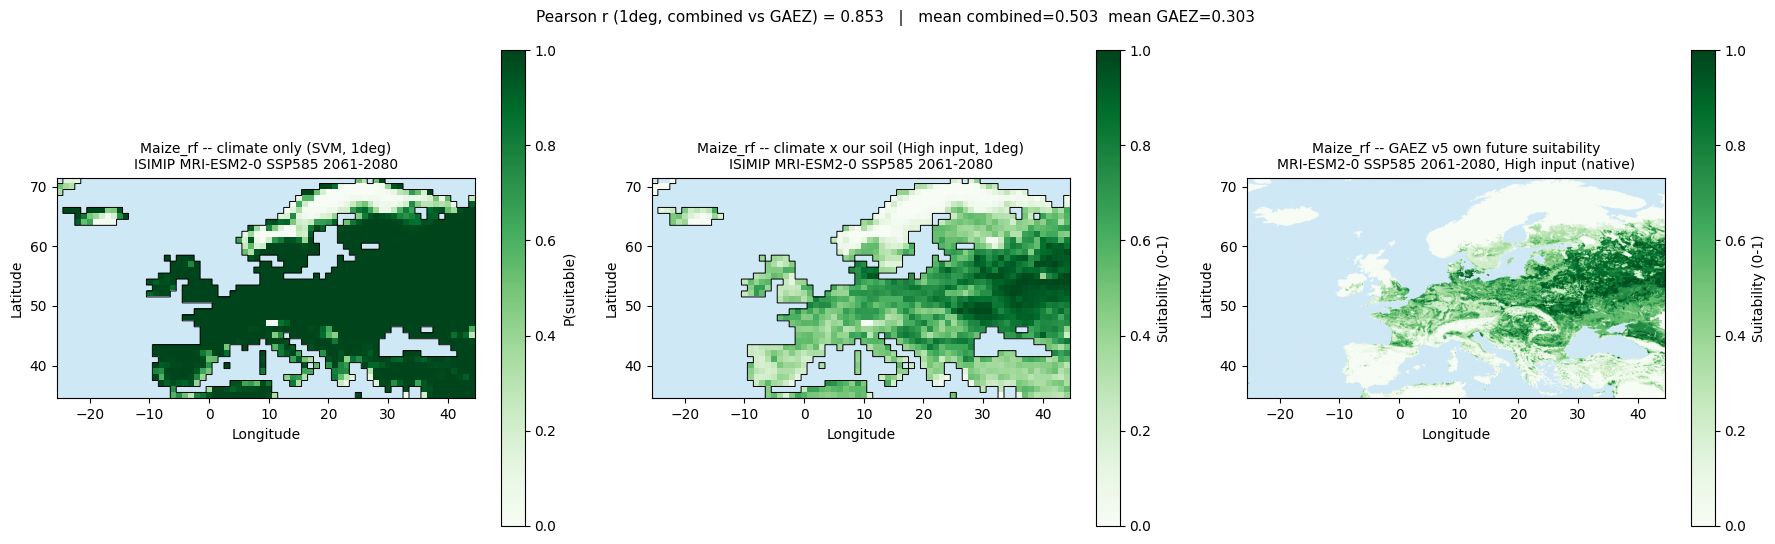

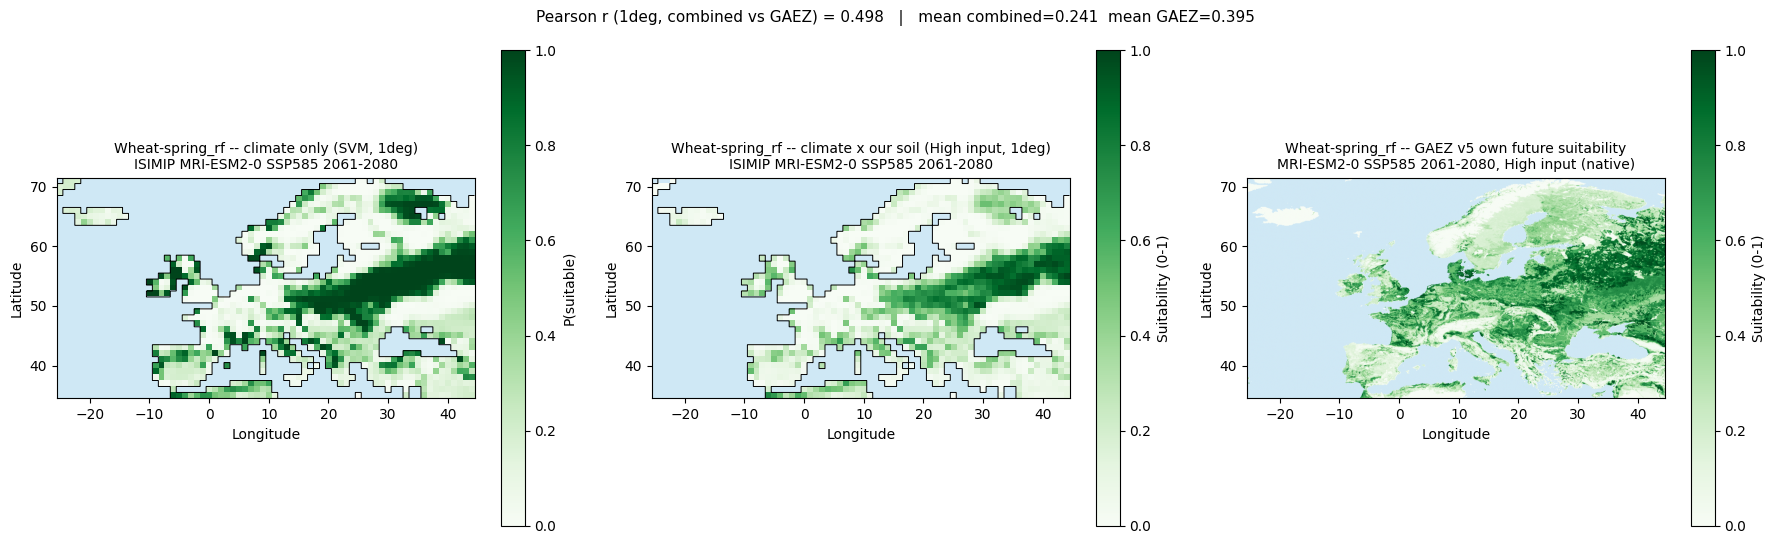

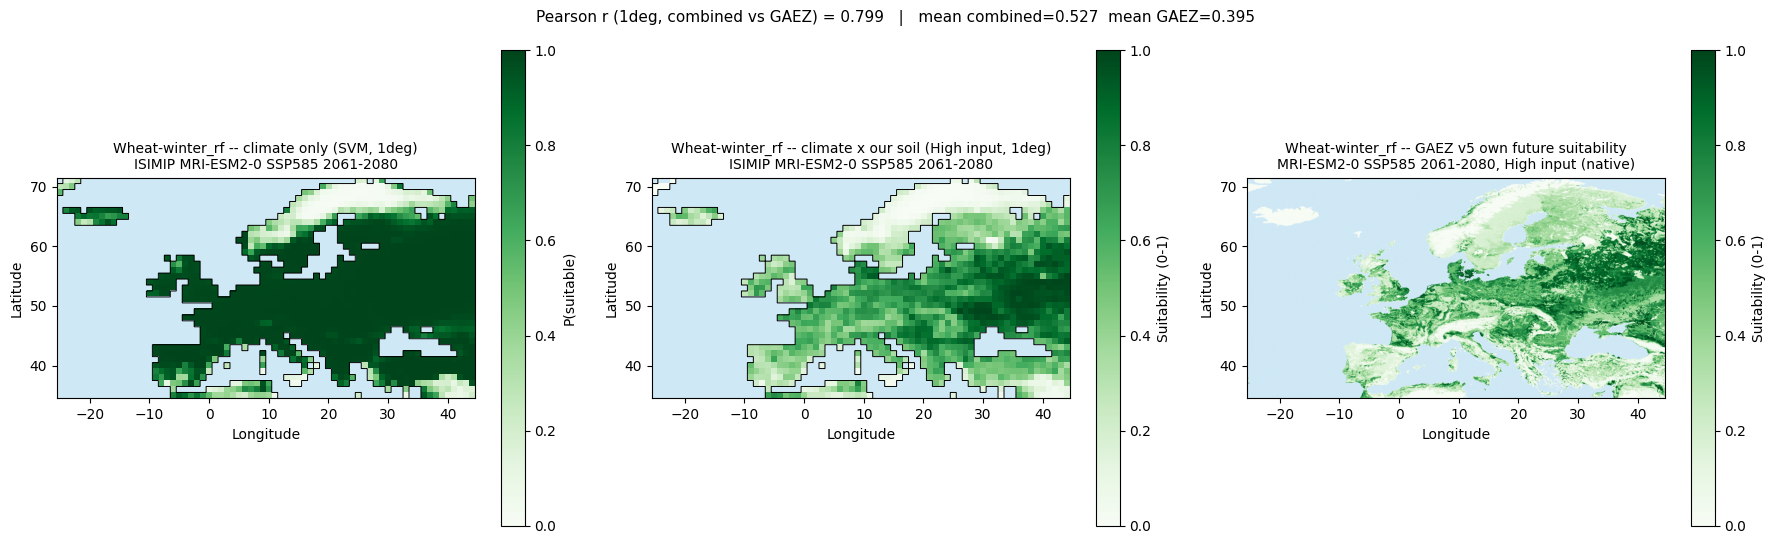

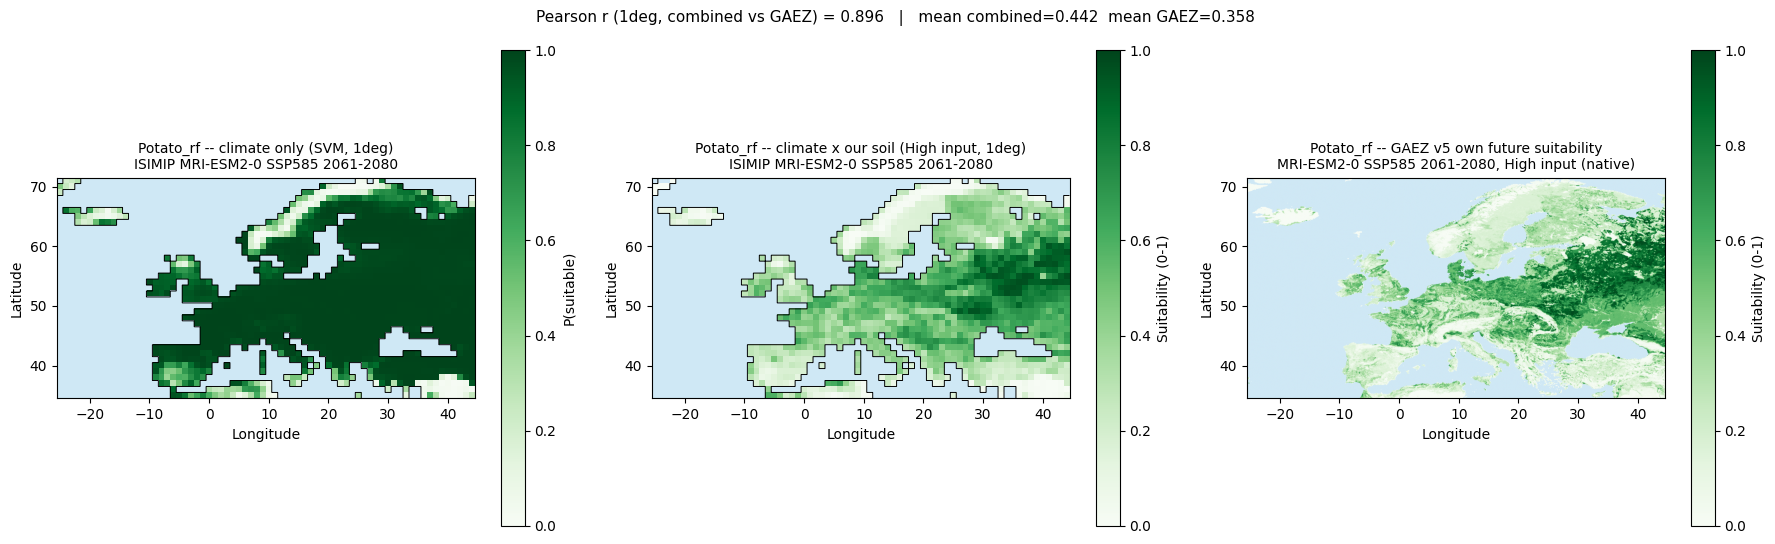

In [4]:
WATER_COLOR = '#cfe8f5'
cmap_suit = plt.get_cmap('Greens').copy()
cmap_suit.set_bad(color=WATER_COLOR)

_UP = 20
_dlat = target_lats_asc[1] - target_lats_asc[0]
_dlon = target_lons[1] - target_lons[0]
LAND_FINE = np.repeat(np.repeat(land_mask.astype(float), _UP, axis=0), _UP, axis=1)
LAT_FINE = np.linspace(target_lats_asc[0] - 0.5*_dlat + 0.5*_dlat/_UP,
                        target_lats_asc[-1] + 0.5*_dlat - 0.5*_dlat/_UP, land_mask.shape[0]*_UP)
LON_FINE = np.linspace(target_lons[0] - 0.5*_dlon + 0.5*_dlon/_UP,
                        target_lons[-1] + 0.5*_dlon - 0.5*_dlon/_UP, land_mask.shape[1]*_UP)


def draw_coastline(ax):
    ax.contour(LON_FINE, LAT_FINE, LAND_FINE, levels=[0.5], colors='black', linewidths=0.7)


for crop in CROPS:
    row = corr_df[(corr_df.crop == crop) & (corr_df.layer == 'combined (climate x soil)')].iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    ax = axes[0]
    ax.set_facecolor(WATER_COLOR)
    im = ax.imshow(suit_climate_future[crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
    draw_coastline(ax)
    ax.set_title(f'{crop} -- climate only (SVM, 1deg)\nISIMIP MRI-ESM2-0 SSP585 2061-2080', fontsize=10)
    plt.colorbar(im, ax=ax, label='P(suitable)')

    ax = axes[1]
    ax.set_facecolor(WATER_COLOR)
    im = ax.imshow(suit_combined_future[crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
    draw_coastline(ax)
    ax.set_title(f'{crop} -- climate x our soil (High input, 1deg)\nISIMIP MRI-ESM2-0 SSP585 2061-2080', fontsize=10)
    plt.colorbar(im, ax=ax, label='Suitability (0-1)')

    ax = axes[2]
    ax.set_facecolor(WATER_COLOR)
    im = ax.imshow(gaez_future_native[crop], origin='upper', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
    ax.set_title(f'{crop} -- GAEZ v5 own future suitability\nMRI-ESM2-0 SSP585 2061-2080, High input (native)', fontsize=10)
    plt.colorbar(im, ax=ax, label='Suitability (0-1)')

    for a in axes:
        a.set_xlabel('Longitude'); a.set_ylabel('Latitude')
    plt.suptitle(f'Pearson r (1deg, combined vs GAEZ) = {row.pearson_r}   |   mean combined={row.ours_mean}  mean GAEZ={row.gaez_mean}', fontsize=11)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'future_isimip_vs_gaez_{crop}.png', dpi=130, bbox_inches='tight')
    plt.show()

## 3bis. Memes cartes, mais "climat x sol" avec le sol a vraie resolution 0.25deg

Identique a la section 3 (climat seul, GAEZ natif inchanges), seul le panneau "climat x sol" change :
au lieu de `soil_high[crop]` (sol deja moyenne a 1deg), charge le sol a vraie resolution 0.25deg
(`soil_suitability_{crop}_0.25deg_x0grid_high.nc`, section 6 de `2.e)`) et duplique le climat 1deg
sur les 4x4 sous-cellules (meme logique que `5.a.ter)` section 3bis/6bis -- voir
[[soil-suitability-module-iv-fixes]]). Nouvelles figures uniquement, celles de la section 3 ne
sont pas touchees.

Maize_rf           (0.25deg): soil mean=0.554  combined_fine mean=0.506  (combined_1deg mean=0.503)
Wheat-spring_rf    (0.25deg): soil mean=0.603  combined_fine mean=0.243  (combined_1deg mean=0.241)
Wheat-winter_rf    (0.25deg): soil mean=0.603  combined_fine mean=0.533  (combined_1deg mean=0.527)
Potato_rf          (0.25deg): soil mean=0.487  combined_fine mean=0.446  (combined_1deg mean=0.442)


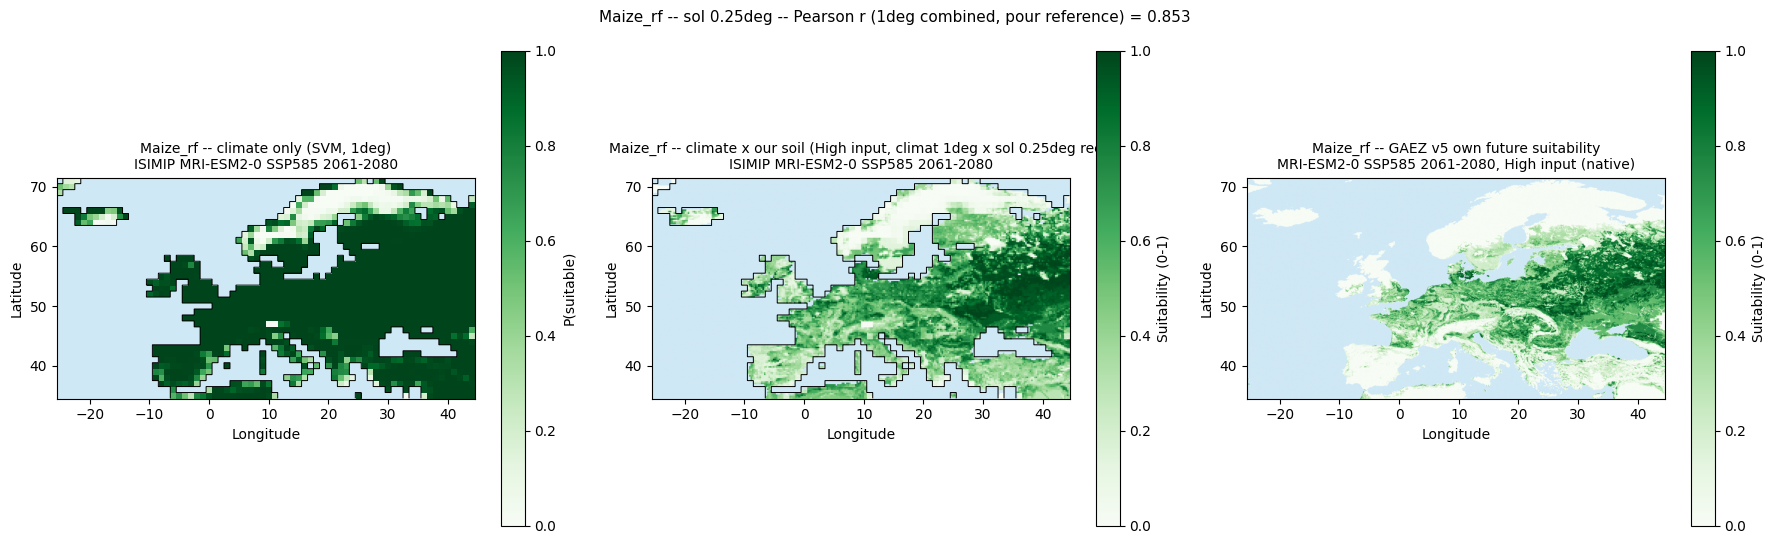

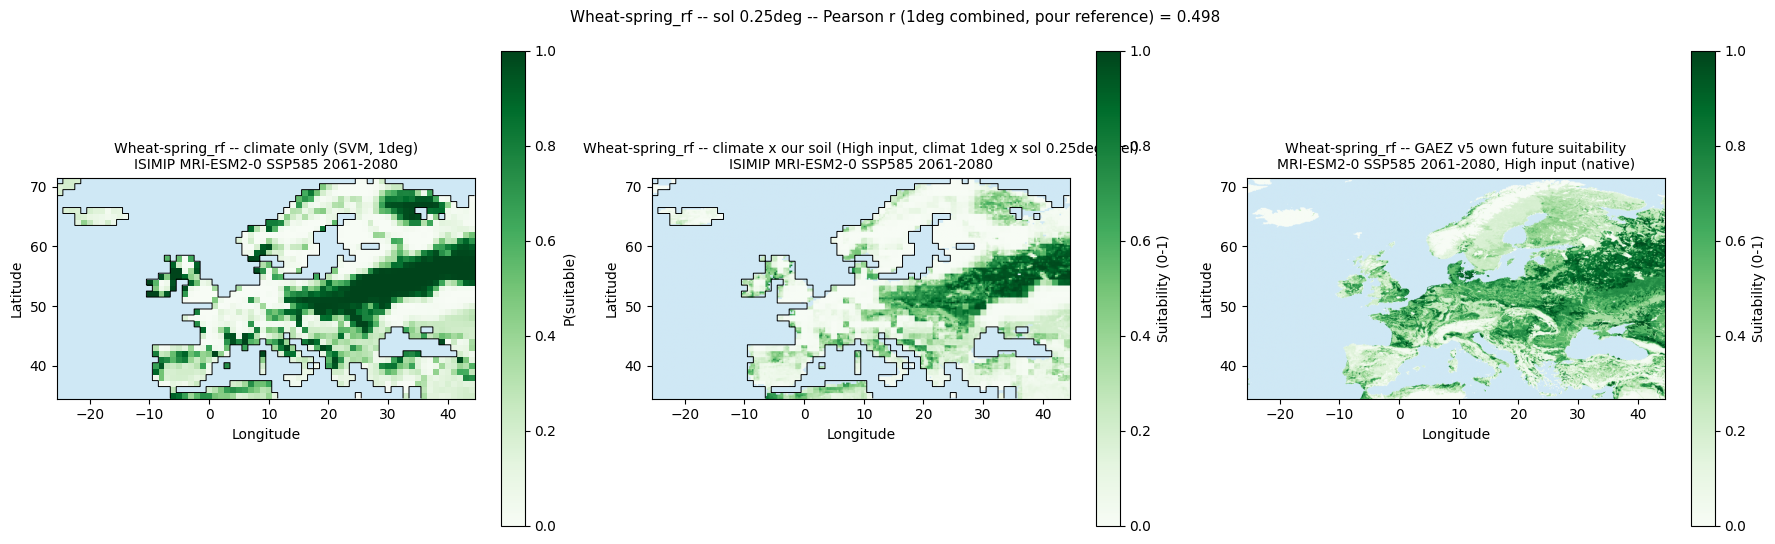

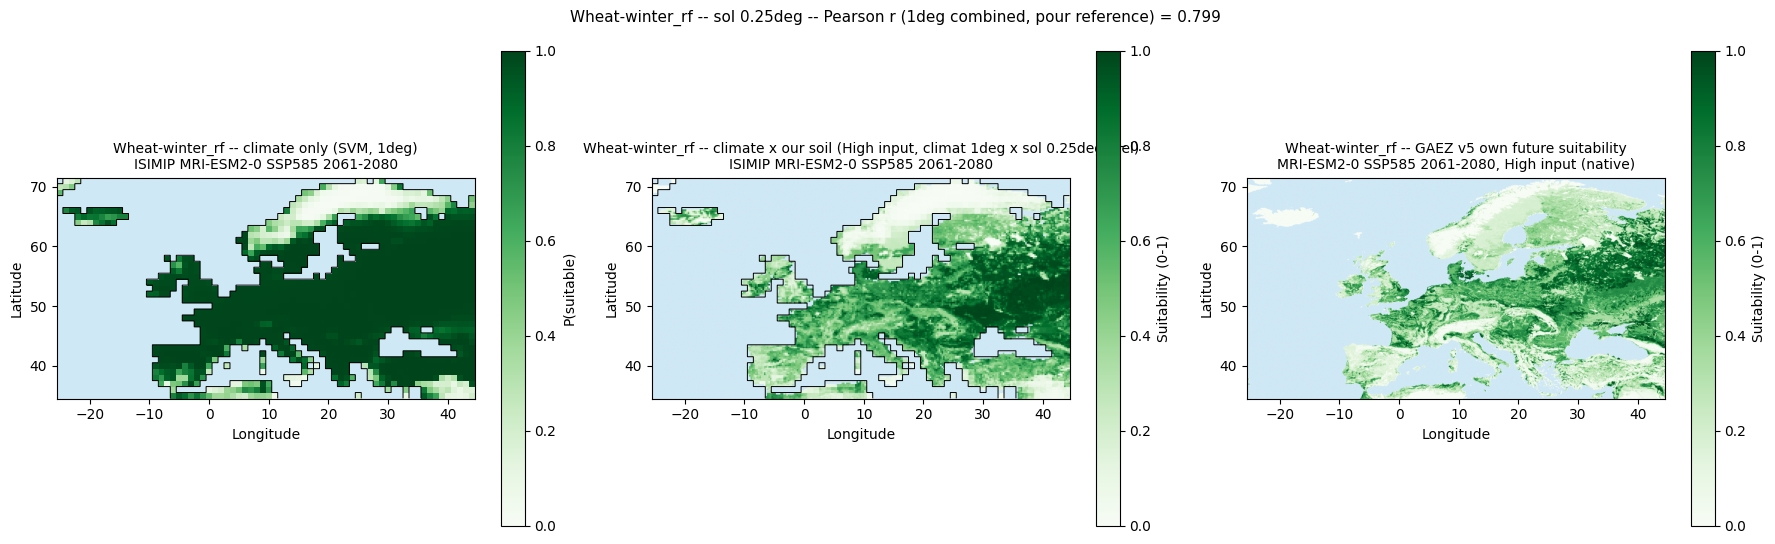

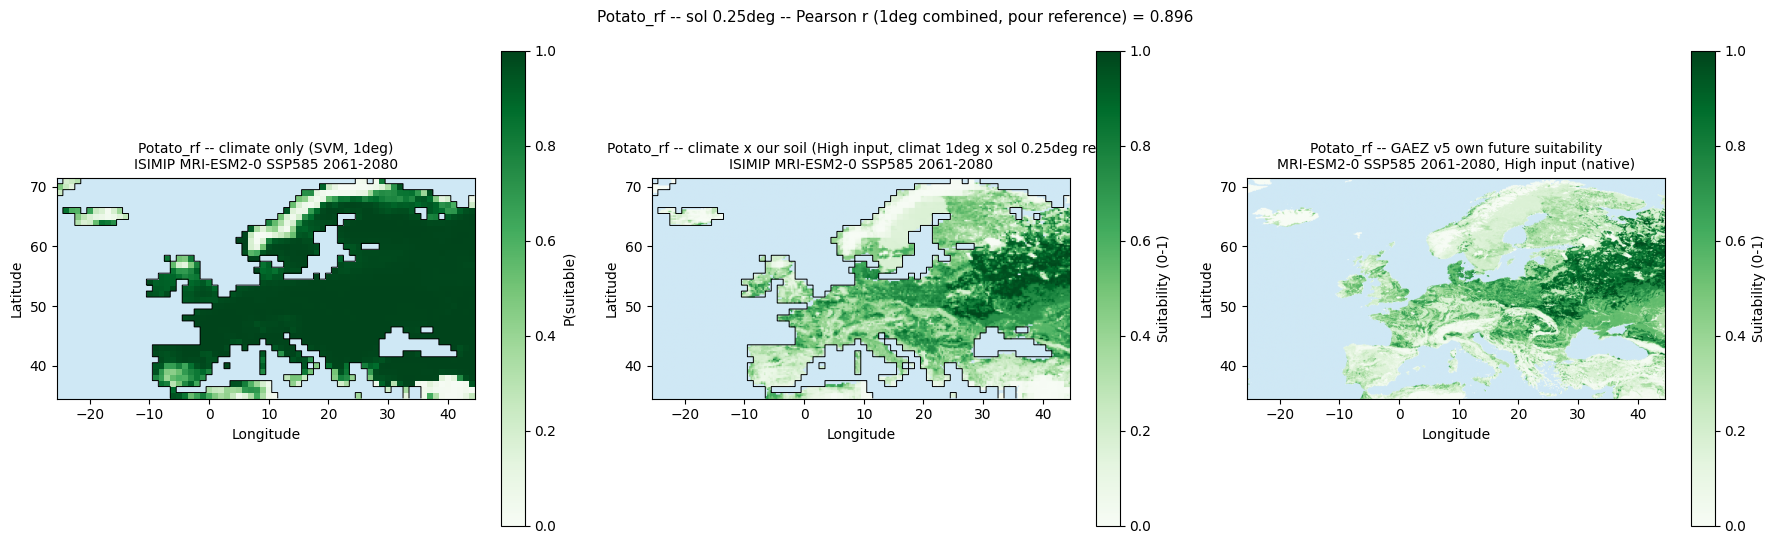

In [5]:
SUB_PER_DEG = 4  # 1deg / 0.25deg

def load_soil_high_fine(crop, res_deg=0.25):
    ds = xr.open_dataset(SOIL_DIR / f'soil_suitability_{crop}_{res_deg}deg_x0grid_high.nc')
    arr = ds[list(ds.data_vars)[0]].values / 100.0
    flat, flon = ds.lat.values, ds.lon.values
    ds.close()
    return arr, flat, flon

fine_lats_ref = fine_lons_ref = None
suit_climate_future_fine = {}
soil_high_fine = {}
suit_combined_future_fine = {}
for crop in CROPS:
    suit_climate_future_fine[crop] = np.repeat(np.repeat(suit_climate_future[crop], SUB_PER_DEG, axis=0), SUB_PER_DEG, axis=1)
    arr, flat, flon = load_soil_high_fine(crop)
    if fine_lats_ref is None:
        fine_lats_ref, fine_lons_ref = flat, flon
    soil_high_fine[crop] = arr
    suit_combined_future_fine[crop] = suit_climate_future_fine[crop] * arr
    print(f'{crop:18s} (0.25deg): soil mean={np.nanmean(arr):.3f}  '
          f'combined_fine mean={np.nanmean(suit_combined_future_fine[crop]):.3f}  '
          f'(combined_1deg mean={np.nanmean(suit_combined_future[crop][land_mask]):.3f})')

fine_ext = [fine_lons_ref[0]-0.125, fine_lons_ref[-1]+0.125, fine_lats_ref[0]-0.125, fine_lats_ref[-1]+0.125]

for crop in CROPS:
    row = corr_df[(corr_df.crop == crop) & (corr_df.layer == 'combined (climate x soil)')].iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    ax = axes[0]
    ax.set_facecolor(WATER_COLOR)
    im = ax.imshow(suit_climate_future[crop], origin='lower', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
    draw_coastline(ax)
    ax.set_title(f'{crop} -- climate only (SVM, 1deg)\nISIMIP MRI-ESM2-0 SSP585 2061-2080', fontsize=10)
    plt.colorbar(im, ax=ax, label='P(suitable)')

    ax = axes[1]
    ax.set_facecolor(WATER_COLOR)
    im = ax.imshow(suit_combined_future_fine[crop], origin='lower', aspect='equal', extent=fine_ext, cmap=cmap_suit, vmin=0, vmax=1)
    draw_coastline(ax)
    ax.set_title(f'{crop} -- climate x our soil (High input, climat 1deg x sol 0.25deg reel)\nISIMIP MRI-ESM2-0 SSP585 2061-2080', fontsize=10)
    plt.colorbar(im, ax=ax, label='Suitability (0-1)')

    ax = axes[2]
    ax.set_facecolor(WATER_COLOR)
    im = ax.imshow(gaez_future_native[crop], origin='upper', aspect='equal', extent=ext, cmap=cmap_suit, vmin=0, vmax=1)
    ax.set_title(f'{crop} -- GAEZ v5 own future suitability\nMRI-ESM2-0 SSP585 2061-2080, High input (native)', fontsize=10)
    plt.colorbar(im, ax=ax, label='Suitability (0-1)')

    for a in axes:
        a.set_xlabel('Longitude'); a.set_ylabel('Latitude')
    plt.suptitle(f'{crop} -- sol 0.25deg -- Pearson r (1deg combined, pour reference) = {row.pearson_r}', fontsize=11)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'future_isimip_vs_gaez_{crop}_sol0.25deg.png', dpi=130, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## Conclusion

This is the closest thing in this pipeline to a genuine out-of-distribution climate test: the SVM
never saw 2061-2080 ISIMIP climate (or any future scenario) during training, and GAEZ's own future
product was computed completely independently (different methodology, same climate input). The
"combined" layer (climate x soil) is what should be compared to GAEZ's own fully-integrated
product -- the climate-only panel is shown alongside for reference but is not the fair comparison
(same reasoning as `5.a)`). A reasonable Pearson r here is much stronger evidence of real climate
transferability than [5.b)](../5.e\)_SVM_temporal_transferability/5.b\)_SVM_temporal_transferability.ipynb)'s historical MIRCA-OS proxy
-- though it still only checks agreement *between two models*, not against any future ground truth
(which cannot exist). Compare these correlations to the historical ones in
[5.a)](../5.a\)_Apply_ERA5_validation_threshold5pct/5.a\)_Apply_ERA5_validation.ipynb)'s `validation_summary_GAEZv5_SIX.csv` for a sense of
whether SVM-vs-GAEZ agreement holds up, improves, or degrades under a real future climate shift.
